# 노드 재시작과 멱등성

**이 노트북에서 할 일**

1. 주문 키를 기록 파일에 한 줄 적는 함수 둘을 만들고, 두 번씩 불러 결과를 견줍니다.
2. 결제 기록을 적는 둘째 노드에서 자식 프로세스를 강제로 끝내고, 다시 실행해 기록 파일을 봅니다.
3. 이미 적힌 키를 건너뛰는 노드로 같은 장면을 만들어, 키가 한 줄만 남는지 확인합니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
01절처럼 매번 같은 값을 내는 우리 노드로, 저장된 값이 맞는지 출력으로 가릅니다.

결제는 실제 결제 서비스를 부르지 않고, 기록 파일에 주문 키를 한 줄 적는 것으로 대신합니다.
실습 폴더 맨 위의 스크립트 `idempotency_worker.py`를 자식 프로세스로 실행합니다.
자식 프로세스는 모두 24번 띄우고, 그중 12번을 강제로 끝냅니다.
6절의 되풀이 장면은 쓰기 방식마다 다섯 번입니다.

노트북은 빈 임시 폴더를 만들어 그 폴더에서 실행합니다.
기록 파일·SQLite 파일·신호 파일은 모두 이 임시 폴더에 생기고, 실습 폴더에는 이 파일들을 남기지 않습니다.
읽어 오는 자료 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 30초 안에 끝났습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
그래프는 langgraph 1.2.11입니다.
SQLite 체크포인터는 langgraph-checkpoint-sqlite 3.0.3에 들어 있습니다.

교재 출력은 Linux의 Python 3.12.13과, 그 Python에 들어 있는 SQLite 3.53.1로 만들었습니다.
프로세스를 강제로 끝내는 방식과 종료 코드는 운영체제마다 다릅니다.
Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
두 함수를 견주고, 결제 기록을 적는 노드를 끊었다가 다시 실행하는 자리입니다.
6절은 같은 장면을 쓰기 방식마다 다섯 번씩 되풀이하는 자리이고, 실습 시간에 실행합니다.
4~6절의 끊는 셀은 실행할 때마다 새 파일을 써서, 다시 실행해도 같은 결과가 나옵니다.
노트북 전체를 처음 값으로 다시 보려면 1절 임시 폴더 셀부터 다시 실행합니다.

실습 폴더 `labs/part6/ch23-persistence`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 상자 다섯이 한 줄로 이어진 흐름도입니다. 첫 파란 상자는 kill_at_second 스크립트를 띄워 charge에서 강제 종료입니다. 둘째 노란 상자는 끊긴 뒤 다음 노드 charge 체크포인트 셋 결제 기록 키 한 줄입니다. 셋째 파란 상자는 start_worker resume 새 자식 프로세스, 넷째 파란 상자는 저장된 다음 노드부터 charge를 처음부터 다시 실행입니다. 다섯째 노란 상자는 다시 실행한 뒤 종료 코드 0 체크포인트 넷인 그림](attachment:06-2-끊고-다시-실행하는-차례.png)

위에서 아래로 한 줄로 읽습니다.
파란 상자는 우리가 부른 함수와 스크립트가 하는 일이고, 노란 상자는 노트북 4·5절 출력입니다.
둘째 상자와 다섯째 상자의 값은 두 쓰기 방식에서 같았습니다.
넷째 상자에서 charge가 결제 기록을 다시 적으려 할 때, 쓰기 방식에 따라 결과가 갈립니다.
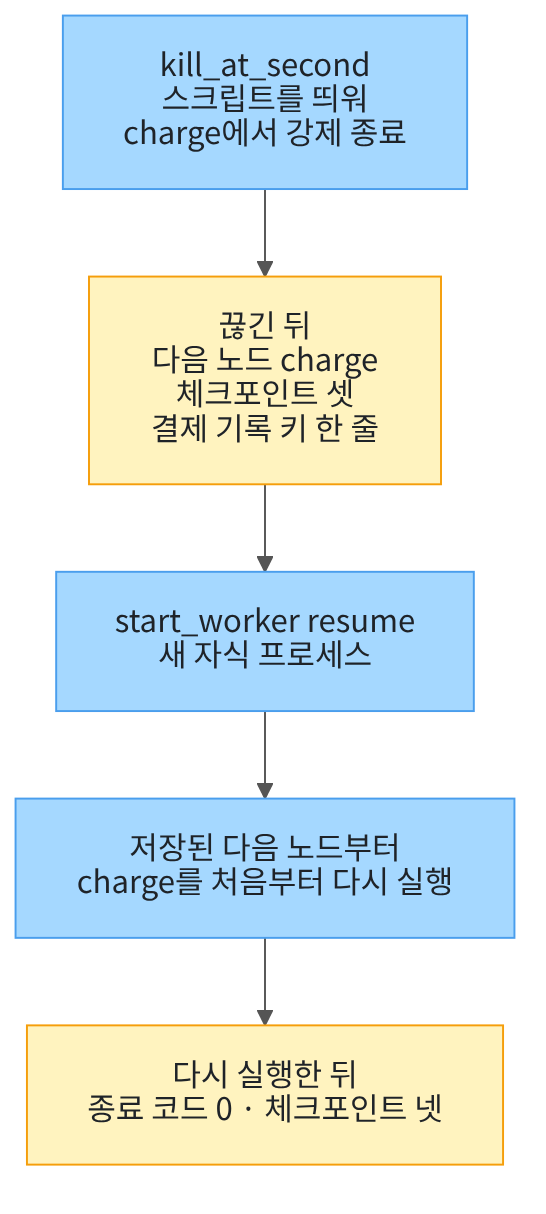

## 1. 준비

04절에서는 자식 프로세스를 둘째 노드에서 강제로 끝낸 뒤 다시 실행했습니다.
그때 저장 시점 `sync`에서도 기록 파일에는 `second`가 두 번 적혔습니다.
이 절은 그 장면을 결제 기록으로 바꿔, 다시 실행된 노드가 바깥에 한 쓰기가 어떻게 되는지 봅니다.
그리고 같은 쓰기를 한 번만 반영하는 방법을 확인합니다.

첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint-sqlite==3.0.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint-sqlite:", version("langgraph-checkpoint-sqlite"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langgraph-checkpoint-sqlite: 3.0.3


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `langgraph-checkpoint-sqlite: 3.0.3`이 보입니다.
두 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프 이름은 Ch 13 01·02절과 같고, 모듈 `os`는 01절 임시 폴더 셀에서 썼습니다.
마지막 줄은 04절에서 배운 함수 다섯을 도구 파일 `checkpoint_tools.py`에서 가져옵니다.

In [2]:
# 그래프 이름(Ch 13 01·02절)과 모듈 os를 가져오고, 04절에서 배운 함수 다섯을 도구 파일에서 가져옵니다
import operator
import os
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from checkpoint_tools import kill_at_second, new_prefix, read_record, read_saved, start_worker

print("도구 파일에서 가져온 함수:", "kill_at_second, new_prefix, read_record, read_saved, start_worker")

도구 파일에서 가져온 함수: kill_at_second, new_prefix, read_record, read_saved, start_worker


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: kill_at_second, new_prefix, read_record, read_saved, start_worker`가 보입니다.
다섯 함수는 04절 노트북 3절과 6절에서 처음 적은 함수입니다.

앞에서 배운 함수는 `checkpoint_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
그래서 임시 폴더로 작업 위치를 옮기기 전에 가져왔습니다.

04절에서는 함수의 인자 `mode`에 저장 시점 이름을 넘겼습니다.
이 절에서는 같은 자리에 쓰기 방식 이름을 넘기고, 스크립트가 넷째 글로 받습니다.
도구 파일의 다섯 함수는 04절 노트북의 함수와 글자까지 같습니다.

다음 셀은 실습 폴더 맨 위의 스크립트 `idempotency_worker.py` 자리를 찾습니다.
04절 자리 찾기 셀과 같은 모양이고, 찾을 파일 이름만 다릅니다.

In [3]:
# 실습 폴더 맨 위의 스크립트 idempotency_worker.py 자리를 찾습니다(임시 폴더로 옮기기 전에 합니다)
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part6/ch23-persistence/idempotency_worker.py"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
# abspath()는 지금 작업 폴더 기준의 자리를, 컴퓨터 맨 위부터 적은 자리 글로 바꿉니다(자리 글은 출력하지 않음)
worker_path = os.path.abspath(root_path + "/labs/part6/ch23-persistence/idempotency_worker.py")
print("worker 파일이 있는가:", os.path.exists(worker_path))

찾은 프로젝트 맨 위: .
worker 파일이 있는가: True


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력을 만든 실행 도구가 도구 파일 폴더를 따로 알려 주어, 이 자리에서도 가져오기가 되었습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
출력 줄 `worker 파일이 있는가: True`로, 스크립트 자리를 변수 `worker_path`에 담았습니다.

다음 셀은 01절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
이 절의 기록 파일·SQLite 파일·신호 파일은 모두 이 임시 폴더에 생깁니다.
자식 프로세스도 이 폴더를 작업 폴더로 물려받아, 같은 폴더에 파일을 씁니다.

In [4]:
# 파일이 생기는지 볼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다(Ch 4 03절과 같은 모양)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
practice_folder = tempfile.mkdtemp(prefix="ch23-06-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
print("임시 폴더 이름에 ch23-06-이 들어 있는가:", "ch23-06-" in practice_folder)
print("현재 작업 폴더의 파일:", os.listdir())

임시 폴더 이름에 ch23-06-이 들어 있는가: True
현재 작업 폴더의 파일: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch23-06-이 들어 있는가: True`로, 이 절의 폴더를 만들었습니다.
출력 줄 `현재 작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.

## 2. 같은 일을 두 번 하면

Ch 17 02절에서는 결제·삭제·보내기처럼 프로그램 바깥의 상태를 바꾸는 동작을 부작용이라고 불렀습니다.
이 절의 부작용은 결제 기록 파일에 주문 키를 한 줄 적는 일입니다.
주문 키는 주문 한 건에 붙인 이름이고, 이 절에서는 `order-2306` 하나를 씁니다.
체크포인트는 그래프의 칸 값과 칸에 낸 갱신을 담을 뿐, 이 파일에 적힌 줄은 저장하지 않습니다.

다음 셀은 기록 파일 끝에 주문 키 한 줄을 덧붙이는 함수입니다.
04절 스크립트의 기록 쓰기처럼 여는 방식 `"a"`로 파일 끝에 이어 씁니다.
적은 뒤에는 한 일을 글 `적음`으로 내놓습니다.

In [5]:
# 기록 파일 끝에 주문 키 한 줄을 덧붙이고, 한 일을 글 "적음"으로 내놓습니다
def append_key(record_name, order_key):
    # 여는 방식 "a"는 파일 끝에 이어 쓰고, 파일이 없으면 새로 만듭니다
    with open(record_name, "a", encoding="utf-8") as record_file:
        record_file.write(order_key + "\n")
    return "적음"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 함수는 파일에 무엇이 적혀 있는지 보지 않고, 부를 때마다 한 줄을 더합니다.

다음 셀은 같은 주문 키로 이 함수를 두 번 부르고, 도구 파일의 `read_record`로 기록 파일을 읽습니다.
실행 전에 예상해 봅니다.
두 번 불렀으니 같은 키가 두 줄 적혀 있을 것입니다.

In [6]:
# 같은 주문 키로 append_key를 두 번 부르고, 기록 파일 twice.record에 적힌 키를 봅니다
order_key = "order-2306"
first_note = append_key("twice.record", order_key)
second_note = append_key("twice.record", order_key)
print("두 번 부른 결과:", first_note, second_note)
twice_keys = read_record("twice.record")
print("기록 파일의 키:", twice_keys)

두 번 부른 결과: 적음 적음
기록 파일의 키: ['order-2306', 'order-2306']


**결과 읽기** — 출력 줄 `두 번 부른 결과: 적음 적음`과 `기록 파일의 키: ['order-2306', 'order-2306']`입니다.
주문은 한 건인데, 결제 기록에는 같은 키가 두 줄 남았습니다.
실제 결제라면 같은 주문을 두 번 결제한 것과 같습니다.

멱등성(idempotency)은 몇 번 실행해도 결과가 한 번 실행한 것과 같은 성질입니다.
엘리베이터 호출 버튼은 여러 번 눌러도 엘리베이터가 한 번만 옵니다.
방금 본 함수 `append_key`는 두 번 부르면 줄이 둘이 되니, 멱등하지 않은 함수입니다.
다음 셀은 이미 적힌 키면 건너뛰는 함수를 만들어, 멱등하게 고칩니다.

In [7]:
# 기록 파일에 같은 주문 키가 이미 있으면 건너뛰고, 없을 때만 한 줄을 덧붙입니다
def append_key_once(record_name, order_key):
    written_keys = []
    # 기록 파일이 있을 때만 읽습니다(처음 부를 때는 파일이 없습니다)
    if os.path.exists(record_name):
        with open(record_name, encoding="utf-8") as record_file:
            written_keys = record_file.read().split()
    if order_key in written_keys:
        return "건너뜀"
    return append_key(record_name, order_key)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 함수는 쓰기 전에 기록 파일을 읽어, 같은 키가 있으면 글 `건너뜀`을 내놓고 끝냅니다.
키가 없을 때만 함수 `append_key`를 불러 한 줄을 적습니다.
함수 `os.path.exists`는 04절에서 신호 파일을 기다릴 때 쓴 함수입니다.

이때 같은 일인지 가르는 값이 주문 키입니다.
멱등 키(idempotency key)는 같은 일을 다시 해도 한 번만 반영하려고, 일마다 붙여 두는 이름입니다.
기보에 수마다 차례 번호를 붙여 두면, 같은 차례의 수를 두 번 적지 않게 할 수 있는 것과 같습니다.
이 절에서는 `order-2306`이 멱등 키이고, 함수는 이 키가 이미 적혀 있는지로 가릅니다.

다음 셀은 같은 주문 키로 이 함수를 두 번 부릅니다.
실행 전에 예상해 봅니다.
첫 번째에는 적고, 두 번째에는 건너뛸 것입니다.

In [8]:
# 같은 주문 키로 append_key_once를 두 번 부르고, 기록 파일 once.record에 적힌 키를 봅니다
first_note = append_key_once("once.record", order_key)
second_note = append_key_once("once.record", order_key)
print("두 번 부른 결과:", first_note, second_note)
once_keys = read_record("once.record")
print("기록 파일의 키:", once_keys)

두 번 부른 결과: 적음 건너뜀
기록 파일의 키: ['order-2306']


**결과 읽기** — 출력 줄 `두 번 부른 결과: 적음 건너뜀`과 `기록 파일의 키: ['order-2306']`입니다.
두 번 불렀지만, 기록 파일에는 한 번 부른 것과 같은 한 줄만 남았습니다.
함수 `append_key_once`는 이 주문 키에 대해 멱등합니다.

## 3. 결제 기록을 적는 스크립트

이제 이 두 함수를 그래프의 노드 안에서 씁니다.
스크립트 `idempotency_worker.py`는 노드 `receive_order` → `charge` 두 개짜리 그래프를 한 번 실행합니다.
둘째 노드 `charge`가 결제 기록 파일에 주문 키를 적고, 04절 스크립트처럼 신호 파일을 만든 뒤 30초를 쉽니다.
스크립트 안의 두 함수는 이 노트북 2절의 두 함수와 글자까지 같습니다.
쓰기 방식이 `naive`면 `append_key`를, `idempotent`면 `append_key_once`를 부릅니다.

저장 시점은 `sync`로 두었습니다.
04절에서 본 대로, 둘째 노드에서 끊겨도 첫째 노드까지의 체크포인트가 남습니다.
끊긴 뒤 파일을 읽으려면, 04절처럼 스크립트와 노드 이름·칸이 같은 설계 객체가 있어야 합니다.
다음 네 셀이 그 설계 객체를 만들고, 이 노트북에서는 그래프를 실행하지 않고 읽기에만 씁니다.
첫 셀은 상태 형식이고, 칸 `order_key`에 주문 키를, 칸 `notes`에 노드가 한 일을 담습니다.

In [9]:
# 주문 키 칸과, 노드가 한 일을 이어 붙이는 칸을 둔 상태 형식을 만듭니다(스크립트와 같은 모양)
class OrderState(TypedDict):
    order_key: str
    notes: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `order_key`는 규칙이 없어 입력한 값이 그대로 들어갑니다.
칸 `notes`에는 Ch 13 02절의 이어 붙이기 규칙을 적었습니다.

다음 셀은 첫째 노드 `receive_order`입니다.
스크립트의 같은 이름 노드와 글자까지 같고, 한 일 `주문 받음`을 칸 `notes`에 냅니다.

In [10]:
# 첫째 노드: 한 일 "주문 받음"을 목록에 담아 냅니다
def receive_order(state):
    return {"notes": ["주문 받음"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 둘째 노드 `charge`의 읽기용 판입니다.
스크립트의 `charge`는 결제 기록 파일에 쓰고 쉬지만, 이 셀의 `charge`는 파일에 쓰지 않습니다.
설계 객체를 읽기에만 쓰므로, 노드 이름과 칸에 내는 모양만 같으면 됩니다.

In [11]:
# 둘째 노드(읽기용): 스크립트의 charge와 같은 칸에 글 하나를 냅니다(이 셀의 charge는 파일에 쓰지 않습니다)
def charge(state):
    return {"notes": ["적음"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노트북에서는 이 노드를 실행하지 않습니다.

다음 셀은 두 노드를 차례로 잇는 설계 객체를 만듭니다.
노드와 엣지를 적는 여섯 줄은 스크립트의 여섯 줄과 글자까지 같습니다.

In [12]:
# 노드 둘을 START → receive_order → charge → END로 잇는 설계 객체를 만듭니다(스크립트와 같은 여섯 줄)
builder = StateGraph(OrderState)
builder.add_node("receive_order", receive_order)
builder.add_node("charge", charge)
builder.add_edge(START, "receive_order")
builder.add_edge("receive_order", "charge")
builder.add_edge("charge", END)
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['receive_order', 'charge']


**결과 읽기** — 출력 줄 `등록한 노드: ['receive_order', 'charge']`입니다.
설계 객체 `builder`는 이 절 끝까지 파일을 읽을 때 씁니다.

## 4. 검사 없이 적는 노드를 끊고 다시 실행하기 (Before)

먼저 쓰기 방식 `naive`로 스크립트를 띄웁니다.
다음 셀은 04절 함수 `kill_at_second`로 스크립트를 띄우고, 둘째 노드에 들어오면 강제로 끝냅니다.
앞머리 글은 04절 함수 `new_prefix`로 고르고, 파일 이름 셋은 그 뒤에 끝말을 붙여 정합니다.
스레드 이름은 `naive`이고, 셀을 다시 실행해도 새 파일을 써서 같은 결과가 나옵니다.

실행 전에 예상해 봅니다.
04절 `sync`처럼 첫째 노드까지의 체크포인트 셋이 남고, 다음 노드는 `charge`일 것입니다.

In [13]:
# 쓰기 방식 naive로 스크립트를 띄워 둘째 노드에서 강제로 끝내고, 파일에 남은 체크포인트를 봅니다
# 셀을 다시 실행해도 앞 실행의 파일과 섞이지 않게, 실행할 때마다 새 앞머리 글을 고릅니다
naive_prefix = new_prefix("naive")
naive_saved = kill_at_second(worker_path, builder, naive_prefix, "naive")
print("남은 칸 값:", naive_saved["칸 값"])
print("다음 노드:", naive_saved["다음 노드"])
print("체크포인트 수:", naive_saved["체크포인트 수"])

남은 칸 값: {'order_key': 'order-2306', 'notes': ['주문 받음']}
다음 노드: ('charge',)
체크포인트 수: 3


**결과 읽기** — 출력 줄 `다음 노드: ('charge',)`와 `체크포인트 수: 3`입니다.
출력 줄 `남은 칸 값: {'order_key': 'order-2306', 'notes': ['주문 받음']}`에는 첫째 노드가 낸 글만 있습니다.
체크포인트에는 노드 `charge`를 마쳤다는 기록이 없습니다.
노드가 끝나야 그 노드가 칸에 낸 갱신이 저장되는데, `charge`는 쉬는 중에 끊겼기 때문입니다.

다음 셀은 끊긴 뒤 결제 기록 파일을 읽습니다.
실행 전에 예상해 봅니다.
노드 `charge`는 쉬기 전에 기록을 적었으니, 키가 이미 한 줄 있을 것입니다.

In [14]:
# 끊긴 뒤 결제 기록 파일에 적힌 키를 봅니다(파일 이름은 kill_at_second가 앞머리 글로 만든 이름과 같습니다)
naive_files = {"sqlite": naive_prefix + ".sqlite", "signal": naive_prefix + ".signal", "record": naive_prefix + ".record"}
naive_before = read_record(naive_files["record"])
print("끊기 전에 적힌 키:", naive_before)

끊기 전에 적힌 키: ['order-2306']


**결과 읽기** — 출력 줄 `끊기 전에 적힌 키: ['order-2306']`입니다.
체크포인트에는 결제를 마친 기록이 없는데, 바깥 파일에는 결제 기록이 이미 한 줄 있습니다.
이 어긋남이 이 절의 문제를 만듭니다.

다음 셀은 새 자식 프로세스로 같은 파일·같은 스레드를 다시 실행합니다.
04절 노트북 4절의 다시 실행 셀과 같은 모양이고, 스크립트는 저장된 다음 노드 `charge`부터 이어 갑니다.
다시 실행 단계에서는 둘째 노드가 쉬지 않으므로, 메서드 `wait`로 끝날 때까지 기다립니다.

In [15]:
# 새 자식 프로세스로 같은 파일·같은 스레드를 다시 실행하고, 끝날 때까지 기다립니다
naive_again = start_worker(worker_path, naive_files, "naive", "resume")
resume_limit = 30
naive_again_code = naive_again.wait(timeout=resume_limit)
print("다시 실행한 프로세스의 종료 코드:", naive_again_code)

다시 실행한 프로세스의 종료 코드: 0


**결과 읽기** — 출력 줄 `다시 실행한 프로세스의 종료 코드: 0`으로, 이번 프로세스는 스스로 끝났습니다.

다음 셀은 다시 실행한 뒤의 체크포인트와 결제 기록 파일을 봅니다.
목록의 메서드 `count`는 같은 값이 몇 번 들어 있는지 셉니다.
실행 전에 예상해 봅니다.
노드 `charge`가 다시 실행되며, 검사 없이 같은 키를 한 줄 더 적을 것입니다.

In [16]:
# 다시 실행한 뒤 남은 칸 값·체크포인트 수와, 결제 기록 파일에 같은 키가 적힌 줄 수를 봅니다
naive_after = read_saved(builder, naive_files["sqlite"], "naive")
print("남은 칸 값:", naive_after["칸 값"])
print("체크포인트 수:", naive_after["체크포인트 수"])
naive_keys = read_record(naive_files["record"])
naive_count = naive_keys.count(order_key)
print("결제 기록 파일의 키:", naive_keys)
print("같은 키가 적힌 줄 수:", naive_count)
# 우리 코드와 저장 시점 sync가 정하는 값이라 실행마다 같아야 합니다
assert naive_count == 2, "쓰기 방식 naive는 같은 키를 두 줄 남겨야 합니다"

남은 칸 값: {'order_key': 'order-2306', 'notes': ['주문 받음', '적음']}
체크포인트 수: 4
결제 기록 파일의 키: ['order-2306', 'order-2306']
같은 키가 적힌 줄 수: 2


**결과 읽기** — 출력 줄 `같은 키가 적힌 줄 수: 2`입니다.
주문은 한 건인데, 결제 기록에 같은 키가 두 줄 남았습니다.
출력 줄 `남은 칸 값: {'order_key': 'order-2306', 'notes': ['주문 받음', '적음']}`의 `적음`은 하나뿐입니다.
체크포인트로 보면 결제는 한 번인데, 바깥 파일에는 두 번 적혔습니다.
이것이 이 절의 Before 결함입니다.

노드 재시작은 끊긴 노드를 이어 갈 때, 그 노드를 처음부터 다시 실행하는 일입니다.
기보에 수를 적은 뒤 사진을 찍기 전에 판이 엎어지면, 사진대로 말을 놓고 그 수를 다시 두는 것과 같습니다.
이 셀에서는 끊긴 `charge`가 새 프로세스에서 처음부터 다시 실행되어, 같은 키를 한 번 더 적었습니다.
출력 줄 `체크포인트 수: 4`는 04절 `sync`를 끝까지 실행한 수와 같습니다.

## 5. 이미 적힌 키를 건너뛰는 노드로 (After)

이제 결함을 고칩니다.
바꾸는 것은 쓰기 방식 하나이고, 스크립트의 `charge`가 `append_key` 대신 `append_key_once`를 부릅니다.
끊는 자리와 다시 실행하는 방법은 4절과 같습니다.

다음 셀은 쓰기 방식 `idempotent`로 스크립트를 띄워 둘째 노드에서 끊고, 남은 체크포인트를 봅니다.
실행 전에 예상해 봅니다.
여기까지는 4절과 같은 값이 나올 것입니다.

In [17]:
# 쓰기 방식 idempotent로 스크립트를 띄워 둘째 노드에서 강제로 끝내고, 파일에 남은 체크포인트를 봅니다
# 셀을 다시 실행해도 앞 실행의 파일과 섞이지 않게, 실행할 때마다 새 앞머리 글을 고릅니다
idempotent_prefix = new_prefix("idempotent")
idempotent_saved = kill_at_second(worker_path, builder, idempotent_prefix, "idempotent")
print("남은 칸 값:", idempotent_saved["칸 값"])
print("다음 노드:", idempotent_saved["다음 노드"])
print("체크포인트 수:", idempotent_saved["체크포인트 수"])

남은 칸 값: {'order_key': 'order-2306', 'notes': ['주문 받음']}
다음 노드: ('charge',)
체크포인트 수: 3


**결과 읽기** — 출력 줄 `다음 노드: ('charge',)`와 `체크포인트 수: 3`은 4절과 같습니다.
출력 줄 `남은 칸 값: {'order_key': 'order-2306', 'notes': ['주문 받음']}`도 같습니다.

다음 셀은 끊긴 뒤 결제 기록 파일을 읽습니다.
처음 부를 때는 파일에 키가 없으니, 이 방식도 한 줄을 적었을 것입니다.

In [18]:
# 끊긴 뒤 결제 기록 파일에 적힌 키를 봅니다(파일 이름은 kill_at_second가 앞머리 글로 만든 이름과 같습니다)
idempotent_files = {"sqlite": idempotent_prefix + ".sqlite", "signal": idempotent_prefix + ".signal", "record": idempotent_prefix + ".record"}
idempotent_before = read_record(idempotent_files["record"])
print("끊기 전에 적힌 키:", idempotent_before)

끊기 전에 적힌 키: ['order-2306']


**결과 읽기** — 출력 줄 `끊기 전에 적힌 키: ['order-2306']`으로, 4절과 같이 한 줄이 적혔습니다.

다음 셀은 4절처럼 새 자식 프로세스로 같은 파일·같은 스레드를 다시 실행합니다.

In [19]:
# 새 자식 프로세스로 같은 파일·같은 스레드를 다시 실행하고, 끝날 때까지 기다립니다
idempotent_again = start_worker(worker_path, idempotent_files, "idempotent", "resume")
resume_limit = 30
idempotent_again_code = idempotent_again.wait(timeout=resume_limit)
print("다시 실행한 프로세스의 종료 코드:", idempotent_again_code)

다시 실행한 프로세스의 종료 코드: 0


**결과 읽기** — 출력 줄 `다시 실행한 프로세스의 종료 코드: 0`입니다.

다음 셀은 다시 실행한 뒤의 체크포인트와 결제 기록 파일을 봅니다.
실행 전에 예상해 봅니다.
노드 `charge`는 이번에도 다시 실행되지만, 키를 찾아 쓰지 않을 것입니다.

In [20]:
# 다시 실행한 뒤 남은 칸 값·체크포인트 수와, 결제 기록 파일에 같은 키가 적힌 줄 수를 봅니다
idempotent_after = read_saved(builder, idempotent_files["sqlite"], "idempotent")
print("남은 칸 값:", idempotent_after["칸 값"])
print("체크포인트 수:", idempotent_after["체크포인트 수"])
idempotent_keys = read_record(idempotent_files["record"])
idempotent_count = idempotent_keys.count(order_key)
print("결제 기록 파일의 키:", idempotent_keys)
print("같은 키가 적힌 줄 수:", idempotent_count)
# 우리 코드와 저장 시점 sync가 정하는 값이라 실행마다 같아야 합니다
assert idempotent_count == 1, "쓰기 방식 idempotent는 같은 키를 한 줄만 남겨야 합니다"

남은 칸 값: {'order_key': 'order-2306', 'notes': ['주문 받음', '건너뜀']}
체크포인트 수: 4
결제 기록 파일의 키: ['order-2306']
같은 키가 적힌 줄 수: 1


**결과 읽기** — 출력 줄 `같은 키가 적힌 줄 수: 1`입니다.
끊고 다시 실행했는데도, 결제 기록에는 한 번 실행한 것과 같은 한 줄만 남았습니다.
출력 줄 `남은 칸 값: {'order_key': 'order-2306', 'notes': ['주문 받음', '건너뜀']}`의 `건너뜀`은 다시 실행된 `charge`가 낸 글입니다.
노드는 다시 실행되었고, 쓰기만 건너뛰었습니다.
출력 줄 `체크포인트 수: 4`는 4절과 같습니다.

## 6. 같은 장면 되풀이하기

4·5절은 쓰기 방식마다 한 번씩만 끊었습니다.
끊는 때가 조금씩 달라도 같은 결과가 나오는지, 같은 장면을 다섯 번씩 되풀이합니다.
먼저 끊기와 다시 실행하기와 기록 읽기를 한 번에 하는 함수를 만듭니다.
이 함수는 도구 파일의 `kill_at_second`·`start_worker`·`read_record`를 차례로 부릅니다.
파일 이름은 앞머리 글을 받아 만들고, 되풀이 셀은 회차마다 함수 `new_prefix`로 새 앞머리를 고릅니다.

In [21]:
# 스크립트를 둘째 노드에서 끊은 뒤 새 자식 프로세스로 다시 실행하고, 결제 기록 파일의 키 목록을 내놓습니다
def kill_then_resume(worker_path, graph_builder, name_prefix, strategy):
    kill_at_second(worker_path, graph_builder, name_prefix, strategy)
    files = {"sqlite": name_prefix + ".sqlite", "signal": name_prefix + ".signal",
             "record": name_prefix + ".record"}
    again = start_worker(worker_path, files, strategy, "resume")
    resume_limit = 30
    again.wait(timeout=resume_limit)
    return read_record(files["record"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 이름의 앞부분은 강제 종료(kill), 뒷부분은 다시 실행(resume)을 뜻합니다.
노트북 전역 이름에 기대지 않고, 스크립트 자리·설계 객체·앞머리 글·쓰기 방식을 모두 인자로 받습니다.

다음 셀은 두 쓰기 방식을 다섯 번씩 되풀이하고, 키가 한 줄만 남은 횟수를 셉니다.
되풀이 수 5는 결과를 보기 전에 정했습니다.
실행 전에 예상해 봅니다.
4·5절처럼 `naive`는 0번, `idempotent`는 5번일 것입니다.

In [22]:
# 쓰기 방식마다 다섯 번씩 끊고 다시 실행해, 결제 기록 파일에 키가 한 줄만 남은 횟수를 셉니다
repeat_count = 5
print("쓰기 방식 | 키가 한 줄만 남은 횟수 | 되풀이 수")
for strategy in ["naive", "idempotent"]:
    once_count = 0
    for i in range(repeat_count):
        # 회차마다 새 앞머리 글을 골라, 셀을 다시 실행해도 앞 실행의 파일과 섞이지 않게 합니다
        name_prefix = new_prefix(strategy)
        keys = kill_then_resume(worker_path, builder, name_prefix, strategy)
        if len(keys) == 1:
            once_count = once_count + 1
    print(strategy, "|", once_count, "|", repeat_count)

쓰기 방식 | 키가 한 줄만 남은 횟수 | 되풀이 수


naive | 0 | 5


idempotent | 5 | 5


**결과 읽기** — 라벨 줄 아래 두 줄은 `naive | 0 | 5`와 `idempotent | 5 | 5`입니다.
다섯 번 모두, 쓰기 방식 `naive`는 같은 키를 두 줄 남겼고 `idempotent`는 한 줄만 남겼습니다.
노트북 밖 준비 확인에서도 두 방식을 스무 번씩 끊어, 한 번도 다른 결과가 나오지 않았습니다.

다음 셀은 작업 폴더에 남은 파일을 봅니다.

In [23]:
# 작업 폴더에 남은 파일 수와, 4절 파일이 있는지 봅니다
file_names = sorted(os.listdir())
print("작업 폴더의 파일 수:", len(file_names))
print("4절 기록 파일 이름:", naive_files["record"])
print("그 파일이 있는가:", naive_files["record"] in file_names)
wal_name = naive_files["sqlite"] + "-wal"
print("4절 SQLite 파일의 옆 파일 -wal이 있는가:", wal_name in file_names)

작업 폴더의 파일 수: 38
4절 기록 파일 이름: naive-1.record
그 파일이 있는가: True
4절 SQLite 파일의 옆 파일 -wal이 있는가: False


**결과 읽기** — 출력 줄 `작업 폴더의 파일 수: 38`입니다.
2절 기록 파일 둘, 4·5절 파일 여섯, 6절 열 번의 파일 셋씩입니다.
출력 줄 `4절 기록 파일 이름: naive-1.record`로, 4절에서 고른 앞머리가 `naive-1`이었습니다.
출력 줄 `4절 SQLite 파일의 옆 파일 -wal이 있는가: False`로, 연결을 모두 닫은 뒤라 옆 파일은 남지 않았습니다.
이 파일들은 모두 임시 폴더에 있어, 실습 폴더에는 남지 않습니다.

## 정리

1. 둘째 노드 안에서 끊긴 뒤 다시 실행하자, 노드 `charge`가 처음부터 다시 실행되었습니다.
2. 검사 없이 적는 쓰기 방식 `naive`는 결제 기록에 같은 키를 두 줄 남겼습니다.
3. 멱등 키가 이미 적혀 있으면 건너뛰는 쓰기 방식 `idempotent`는 한 줄만 남겼습니다.

07절 실습에서는 이 챕터에서 배운 것을 작은 흐름 하나에 모아 실행합니다.